# What is Memory in Agentic Graph?

Memory in an Agentic Graph allows an AI agent to store, retrieve, and use information across different workflow steps or conversations.

It helps agents remember previous interactions, intermediate results, user preferences, and important decisions instead of starting from scratch every time.

In frameworks like **LangGraph**, memory helps maintain state and enables agents to build context over time.

---

## Why Do Agents Need Memory?

### Without Memory

- The agent may forget previous conversation details.
- Each execution starts with limited context.
- The agent cannot easily maintain progress across multiple steps.

### With Memory

- The agent remembers previous interactions.
- Maintains task progress.
- Reuses previously collected information.
- Provides more personalized responses.

---

## Types of Memory in Agentic Graphs

### 1. Short-Term Memory (Working Memory)

Stores information during an ongoing conversation or workflow execution.

**Example:**

User: "My name is Aakash."

Agent: "Nice to meet you, Aakash!"

User: "What is my name?"

Agent: "Your name is Aakash."

The agent remembers the information within the conversation.

In LangGraph, this is commonly managed using **checkpoints and state** associated with a conversation thread.

---

### 2. Long-Term Memory

Stores information that can be retrieved across different conversations or workflow executions.

**Examples:**

- User prefers concise explanations.
- User is learning LangGraph.
- User prefers Python examples.

The agent can retrieve these details in future interactions.

Long-term memory is commonly implemented using **databases or vector stores**.

---

## Short-Term vs Long-Term Memory

| Feature | Short-Term Memory | Long-Term Memory |
|---|---|---|
| **Scope** | Current thread or workflow | Across conversations |
| **Purpose** | Maintain immediate context | Retain reusable information |
| **Storage** | Checkpoints / State | Database / Vector store |
| **Example** | Previous messages in current chat | User preferences |


### Streaming

In [24]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
load_dotenv()

llm=init_chat_model("groq:openai/gpt-oss-20b")

class State(TypedDict):
    messages:Annotated[list,add_messages]

In [29]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

def superbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

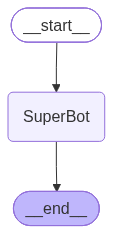

In [30]:
from langgraph.graph import StateGraph,START,END

graph=StateGraph(State)

graph.add_node("SuperBot",superbot)
graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder=graph.compile(checkpointer=memory)
graph_builder

In [31]:
config = {"configurable":{"thread_id":"1"}}
graph_builder.invoke({'messages':"Hi, My name is Aakash The king,I am an AI Engineer"},config)

{'messages': [HumanMessage(content='Hi, My name is Aakash The king,I am an AI Engineer', additional_kwargs={}, response_metadata={}, id='9f7a9f7b-192c-41b5-8db4-c6b788009034'),
  AIMessage(content='Hello Aakash! 👋 It’s great to meet an AI engineer. What kind of projects are you working on right now? Are you diving into any particular frameworks or research areas? Feel free to share—happy to chat or help out if you have questions!', additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Aakash The king,I am an AI Engineer". They are greeting. We need to respond. Probably ask about their work or something. Also note that the user is a developer. We should comply with policy. There\'s no disallowed content. It\'s fine. We\'ll respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 127, 'prompt_tokens': 85, 'total_tokens': 212, 'completion_time': 0.136337618, 'completion_tokens_details': {'reasoning_tokens': 65}, 'prompt_time': 0.020252136, 'prompt_toke

In [32]:
config = {"configurable":{"thread_id":"1"}}
graph_builder.invoke({'messages':"Can you tell me something about me?"},config)

{'messages': [HumanMessage(content='Hi, My name is Aakash The king,I am an AI Engineer', additional_kwargs={}, response_metadata={}, id='9f7a9f7b-192c-41b5-8db4-c6b788009034'),
  AIMessage(content='Hello Aakash! 👋 It’s great to meet an AI engineer. What kind of projects are you working on right now? Are you diving into any particular frameworks or research areas? Feel free to share—happy to chat or help out if you have questions!', additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Aakash The king,I am an AI Engineer". They are greeting. We need to respond. Probably ask about their work or something. Also note that the user is a developer. We should comply with policy. There\'s no disallowed content. It\'s fine. We\'ll respond politely.'}, response_metadata={'token_usage': {'completion_tokens': 127, 'prompt_tokens': 85, 'total_tokens': 212, 'completion_time': 0.136337618, 'completion_tokens_details': {'reasoning_tokens': 65}, 'prompt_time': 0.020252136, 'prompt_toke

# Types of Streaming

## 1. `.stream()` vs `.astream()`

These decide **how Python waits for graph results**.

### `.stream()` — Synchronous

- Uses `for`
- Processes results one by one
- Waits for each result
- Good for simple scripts

Example:

    for chunk in graph.stream(input):
        print(chunk)

Flow:

    Graph → Chunk 1 → Chunk 2 → Chunk 3 → Done

### `.astream()` — Asynchronous

- Uses `async for`
- Works with `async/await`
- Useful for APIs, web apps, chat apps, and concurrent tasks
- Can handle other async work while waiting

Example:

    async for chunk in graph.astream(input):
        print(chunk)

Flow:

    Task 1 ─────────→ Result 1
    Task 2 ─────→ Result 2
    Task 3 ─────────→ Result 3

    Tasks can run concurrently while waiting.

> **Note:** Async does not make one API call faster. It helps handle multiple waiting/I/O operations efficiently.

## 2. `stream_mode`

`stream_mode` tells LangGraph **what information you want to receive while the graph runs**.

---

### 🔹 `stream_mode="values"`

Returns the **full current state** after each node executes.

> 💬 *"Give me the entire current state."*

**Example:**

```text
Initial State
{
    "name": "Aakash",
    "age": 22
}
        │
        ▼  Node A runs
        │
Full State (emitted)
{
    "name": "Aakash",
    "age": 23
}
```

---

### 🔹 `stream_mode="updates"`

Returns **only the changes** made by each node, not the full state.

> 💬 *"Give me only what changed."*

**Example:**

```text
Initial State
{
    "name": "Aakash",
    "age": 22
}
        │
        ▼  Node A runs
        │
Update (emitted)
{
    "node_a": {
        "age": 23
    }
}
```

> 📝 **Note:** In `updates` mode, each chunk is keyed by the **node name** that produced it, so you can tell which node made which change.

---

### ⚖️ Quick Difference

| Aspect            | `values`                   | `updates`               |
| ----------------- | -------------------------- | ----------------------- |
| **What you get**  | Full state                 | Only the changes        |
| **When**          | After each node            | After each node         |
| **Output shape**  | `{ ...entire state }`      | `{ node_name: {...} }`  |
| **Question**      | *"What is the state now?"* | *"What changed?"*       |
| **Best for**      | Inspecting/debugging state | Tracking node activity  |

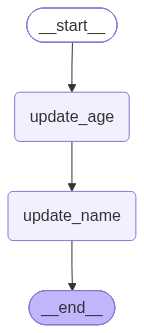

In [19]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph,START,END

class StreamTest(TypedDict):
    name: str
    age:int


def update_age(state:StreamTest):
    return{"age":23}

def update_name(state:StreamTest):
    return{"name":"Aakash The King"}

graph=StateGraph(StreamTest)

graph.add_node("update_age",update_age)
graph.add_node("update_name",update_name)

graph.add_edge(START,"update_age")
graph.add_edge("update_age","update_name")
graph.add_edge("update_name",END)

app=graph.compile()
app

In [16]:
input_data = {
    "name": "Aakash",
    "age": 22
}

In [22]:
## Using Values
for chunk in app.stream(
    input_data,
    stream_mode="values"
):
    print(chunk)
    

{'name': 'Aakash', 'age': 22}
{'name': 'Aakash', 'age': 23}
{'name': 'Aakash The King', 'age': 23}


In [23]:
## Using updates
for chunk in app.stream(
    input_data,
    stream_mode="updates"
):
    print(chunk)

{'update_age': {'age': 23}}
{'update_name': {'name': 'Aakash The King'}}


In [37]:
config = {"configurable":{"thread_id":"3"}}

for chunk in graph_builder.stream({'messages':"Hi,my name is Aakash and i love play station"},config,stream_mode="updates"):
    # print(chunk["SuperBot"]["messages"][0].content)
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hey Aakash! 👋 I’m happy to hear you’re a PlayStation fan. Is there a particular game, console feature, or gaming topic you’d like to chat about? Just let me know!', additional_kwargs={'reasoning_content': "The user repeats same message. They haven't asked a question. According to policy, we should respond politely, maybe ask what they'd like to know. We should not ask for personal info beyond name. We can ask what they want to talk about."}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 297, 'total_tokens': 398, 'completion_time': 0.10400735, 'completion_tokens_details': {'reasoning_tokens': 50}, 'prompt_time': 0.016696149, 'prompt_tokens_details': None, 'queue_time': 0.210453228, 'total_time': 0.120703499}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_a12402de73', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a0d80f-3cd8-7222

In [41]:
config = {"configurable":{"thread_id":"3"}}

for chunk in graph_builder.stream({'messages':"Hi,my name is Aakash and i love play kabbadii"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,my name is Aakash and i love play station', additional_kwargs={}, response_metadata={}, id='a8e1ba33-428a-44fe-890d-38e628b43be5'), AIMessage(content='Hello Aakash! That’s awesome—PlayStation has such an exciting lineup. I’m ready to help with anything you’d like to explore, from game recommendations to tips and tricks. Just let me know what you’re curious about!', additional_kwargs={'reasoning_content': 'The user says "Hi, my name is Aakash and i love play station". The user likely wants a conversation. The instruction says: "When a user says something, respond with a greeting that acknowledges the user and their interests. If the user says something that is not a question or request, respond with a statement that acknowledges what the user said and that you are ready to help. Do not ask or repeat the user question." So we should respond with a greeting acknowledging that the user is Aakash and loves PlayStation. Also we should say we are ready t

In [46]:
config = {"configurable": {"thread_id": "4"}}

async for chunk in graph_builder.astream_events({'messages':"Hi,my name is Aakash and i love play station"},config,stream_mode="updates"):
    print(chunk)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'Hi,my name is Aakash and i love play station'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a0d81b-1290-7fb2-8ab9-d8b244a8400e', 'metadata': {'thread_id': '4', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi,my name is Aakash and i love play kabbadii', additional_kwargs={}, response_metadata={}, id='43259074-9069-4b29-a9b3-6db4d8b37d92'), AIMessage(content='Hey Aakash! 👋 It’s great to meet someone who’s into kabaddi. That sport is full of strategy, speed, and a lot of fun. Do you play it yourself, or are you a big fan of watching the matches? Let me know if you want to chat more about kabaddi, or anything else you’re into!', additional_kwargs={'reasoning_content': 'The user says "Hi, my name is Aakash and i love play kabbadii". The assistant should respond in a friendly manner. Possibly mention interest in kabbadi. There\'s no special req

In [47]:
config = {"configurable": {"thread_id": "5"}}

async for chunk in graph_builder.astream_events({'messages':"Hi,my name is Aakash and i love play station"},config,stream_mode="values"):
    print(chunk)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'Hi,my name is Aakash and i love play station'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a0d821-1179-7892-8065-5ba78de05169', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_stream', 'run_id': '01a0d821-1179-7892-8065-5ba78de05169', 'name': 'LangGraph', 'tags': [], 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'data': {'chunk': {'messages': [HumanMessage(content='Hi,my name is Aakash and i love play station', additional_kwargs={}, response_metadata={}, id='142945b1-1b1b-4ac9-b236-53601d1708b7')]}}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hi,my name is Aakash and i love play station', additional_kwargs={}, response_metadata={}, id='142945b1-1b1b-4ac9-b236-53601d1708b7')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a0d821-117d-72d3-ba54-21c1b6b1ce11', 'metadata': {'thread_id': 